In [ ]:
%pip install scikit-image

In [ ]:
%pip install pandas

## PL08-PL11: doplňkové analýzy, audity a grafy
Tento krok generuje CSV a PNG. PDF buňky se navíc ověřují čtením originálu; programové srovnání nenahrazuje kontrolu extrakce.

Program zpracuje dva černobílé obrázky částic: castice_ciste.png a castice_spojene.png.

1. Načte každý obrázek ze složky data/obrazy a převede ho na odstíny šedi.
2. Vyhodnotí šest prahových hodnot (0, 64, 127, 200, 254 a 255). Pro každý práh označí souvislé oblasti pixelů, jejichž jas je menší nebo roven prahu. Použije 8-sousednost, takže se za sousední považují i pixely dotýkající se diagonálně. Do threshold_records uloží název obrázku, práh, počet oblastí a celkový počet vyhovujících pixelů.
3. Při prahu 127 změří jednotlivé oblasti: jejich plochu v pixelech, odhad plochy v mm² (dělením 100) a souřadnice středu. Tyto údaje ukládá do image_records. Souřadnice stred_x a stred_y odpovídají sloupcové a řádkové souřadnici středu.
4. Vykreslí obrázek s obrysy označených oblastí a očísluje je šipkami. Nadpis uvádí počet oblastí, práh a použitou sousednost. Graf zobrazí pomocí plt.show() a následně jej předá funkci finish pod názvem začínajícím pl09_.

Proměnné threshold_records a image_records tak shromažďují souhrnné výsledky pro pozdější zpracování.

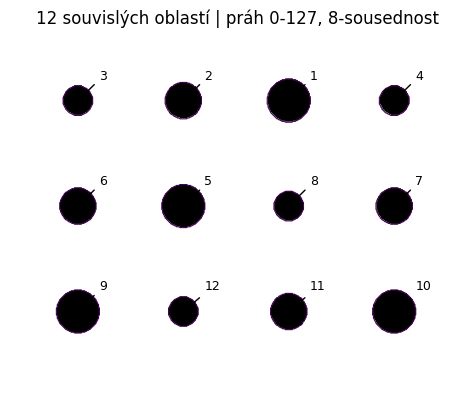

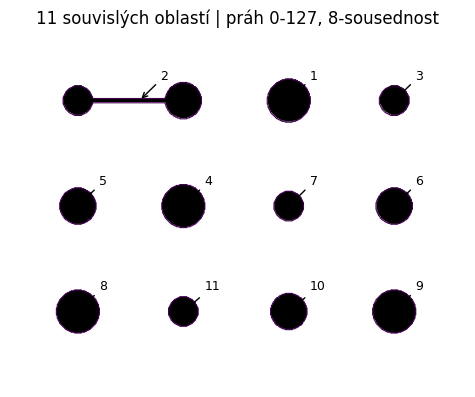

,obraz,oblast,plocha_px,plocha_mm2,stred_x,stred_y
0,castice_ciste.png,1,2025,20.25,330.000000,80.0
1,castice_ciste.png,2,1441,14.41,205.000000,80.0
2,castice_ciste.png,3,957,9.57,80.000000,80.0
3,castice_ciste.png,4,957,9.57,455.000000,80.0
4,castice_ciste.png,5,2025,20.25,205.000000,205.0
5,castice_ciste.png,6,1441,14.41,80.000000,205.0
6,castice_ciste.png,7,1441,14.41,455.000000,205.0
7,castice_ciste.png,8,957,9.57,330.000000,205.0
8,castice_ciste.png,9,2025,20.25,80.000000,330.0
9,castice_ciste.png,10,2025,20.25,455.000000,330.0


,obraz,prah,pocet,plocha_px
0,castice_ciste.png,0,12,17692
1,castice_ciste.png,64,12,17692
2,castice_ciste.png,127,12,17692
3,castice_ciste.png,200,12,17692
4,castice_ciste.png,254,12,17692
5,castice_ciste.png,255,1,226800
6,castice_spojene.png,0,11,18122
7,castice_spojene.png,64,11,18122
8,castice_spojene.png,127,11,18122
9,castice_spojene.png,200,11,18122


In [33]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
from PIL import Image

import numpy as np
from collections import Counter

import json, re, sys, platform

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p/'data').is_dir() and (p/'reseni/pipeline.py').exists()), None)

data=ROOT/'data'; out=ROOT/'vysledky/doplnkove'; out.mkdir(exist_ok=True,parents=True)

def save(df: pd.DataFrame, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, sep=';', index=False, encoding='utf-8-sig', decimal=',')

plots=ROOT/'ukazky'; plots.mkdir(exist_ok=True)

def finish(fig,name):
    fig.tight_layout(rect=[0,0.045,1,1]); 
    fig.text(.015,.01, 'Zdroj: syntetická data výukového kurzu; vlastní výpočet.',fontsize=7); 
    fig.savefig(plots/name,dpi=160,bbox_inches='tight');
    plt.close(fig)

def run():
    #stats={}
    plots=ROOT/'ukazky'; 
    plots.mkdir(exist_ok=True)
    image_records=[];
    threshold_records=[]

    for name in ['castice_ciste.png','castice_spojene.png']:
        arr=np.asarray(Image.open(data/'obrazy'/name).convert('L'))
        for threshold in [0,64,127,200,254,255]:
            labs,n=ndimage.label(arr<=threshold,structure=np.ones((3,3)))
            threshold_records.append(dict(obraz=name,prah=threshold,pocet=n,plocha_px=int((arr<=threshold).sum())))
        labs,n=ndimage.label(arr<=127,structure=np.ones((3,3)))
        areas=np.bincount(labs.ravel())[1:]
        centers=ndimage.center_of_mass(arr<=127,labs,range(1,n+1))
        for j,(area,center) in enumerate(zip(areas,centers),1):
            image_records.append(dict(obraz=name,oblast=j,plocha_px=int(area),plocha_mm2=float(area/100),stred_x=float(center[1]),stred_y=float(center[0])))
        fig,ax=plt.subplots(figsize=(6.4,4.6))
        ax.imshow(arr,cmap='gray',vmin=0,vmax=255)
        ax.contour(labs>0,levels=[.5],linewidths=.8)
        for j,(y,x) in enumerate(centers,1):
            ax.annotate(str(j),(x,y),xytext=(x+25,y-25),arrowprops=dict(arrowstyle='->'),fontsize=9)
        ax.set_axis_off();
        ax.set_title(f'{n} souvislých oblastí | práh 0-127, 8-sousednost')
        plt.show()
        finish(fig,'pl09_'+name)
    
    save(pd.DataFrame(image_records),out/'pl09_plochy.csv')
    display(pd.DataFrame(image_records))
    save(pd.DataFrame(threshold_records),out/'pl09_citlivost.csv')
    display(pd.DataFrame(threshold_records))
    #stats['obrazy']=image_records
    
run()

In [ ]:
def cz(s):
    maps = {'~a':'\u00e1','~e':'\u00e9','~i':'\u00ed','~o':'\u00f3','~u':'\u00fa','~y':'\u00fd',
            '^c':'\u010d','^d':'\u010f','^e':'\u011b','^n':'\u0148','^r':'\u0159','^s':'\u0161','^t':'\u0165','^z':'\u017e','@u':'\u016f',
            '~Y':'\u00dd','~O':'\u00d3','^D':'\u010e','^E':'\u011a','^N':'\u0147','^T':'\u0164','~A':'\u00c1','~E':'\u00c9','~I':'\u00cd','~U':'\u00da','^C':'\u010c','^R':'\u0158','^S':'\u0160','^Z':'\u017d','@U':'\u016e'}
    for a,b in maps.items(): s=s.replace(a,b)
    return s

def aggregate(df: pd.DataFrame, keys: list[str]) -> pd.DataFrame:
    g = df.groupby(keys, as_index=False, dropna=False)[NUM].sum(min_count=1)
    g['podil_zpozdenych'] = g.pocet_zpozdenych / g.pocet_zasilek.where(g.pocet_zasilek.ne(0))
    return g

def text():
    stats={}
    clean=pd.read_csv(ROOT/'vysledky/zaklad/pl04_analyticka.csv',sep=';',decimal=',',encoding='utf-8-sig')
    texts=pd.read_csv(data/'texty/zpetna_vazba.csv',sep=';',encoding='utf-8-sig')
    stop=set((data/'texty/stopslova.txt').read_text(encoding='utf-8').split())
    words=re.findall(r'[^\W\d_]+',' '.join(texts.text).lower(),flags=re.UNICODE)
    all_counts=Counter(words);filtered_counts=Counter(w for w in words if w not in stop)
    counts=pd.DataFrame([(k,v,filtered_counts[k]) for k,v in sorted(all_counts.items(),key=lambda kv:(-kv[1],kv[0]))],columns=['vyraz','bez_filtru','po_stopslovech'])
    save(counts,out/'pl08_frekvence.csv')
    found=texts[texts.text.str.contains(cz(r'\bpozd^e\b'),case=False,regex=True)].copy()
    found['referent']=found.text_id.map({'T01':cz('z~asilka'),'T03':cz('z~asilka'),'T05':cz('ozn~amen~i'),'T08':cz('z~asilka'),'T12':cz('z~asilka')})
    save(found,out/'pl08_kontexty.csv');stats['texty']=dict(tokens=len(words),tokens_filtered=sum(filtered_counts.values()),vocab=len(all_counts),vocab_filtered=len(filtered_counts),pozdne_ids=found.text_id.tolist(),top=counts.head(15).to_dict('records'))
    expected=aggregate(clean[clean.mesic.eq('2025-01')],['pobocka_id'])[['pobocka_id','pocet_zasilek','pocet_zpozdenych']]
    ocr=pd.read_csv(data/'dokumenty/ocr_simulovane_chyby.csv',sep=';',encoding='utf-8-sig')
    save(expected,out/'pl08_pdf_opravene.csv');errors=[]



In [32]:
from pathlib import Path
import sys
import subprocess
import json
import pandas as pd

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p/'data').is_dir() and (p/'reseni/pipeline.py').exists()), None)

result = subprocess.run([sys.executable, str(ROOT/'reseni/analyzy.py')], cwd=ROOT, text=True, capture_output=True)
if result.returncode:
    raise RuntimeError(result.stderr)
extra = json.loads((ROOT/'vysledky/doplnkove/vsechny_vysledky.json').read_text(encoding='utf-8'))
print('Supplementary calculations completed.')
pd.read_csv(ROOT/'vysledky/doplnkove/pl08_audit_ocr.csv', sep=';', encoding='utf-8-sig')

Supplementary calculations completed.


,pobocka_id,sloupec,puvodni,spravne,strana
0,B02,pocet_zasilek,4900,490,1
1,B05,pocet_zpozdenych,25,24,1


# Active Contours
Následující skript je výukový program pro segmentaci obrazu pomocí aktivních kontur (tzv. „hadů“ / snakes) napsaný s využitím knihovny scikit-image. Ukazuje, jak se počáteční kruhová křivka postupně smršťuje a tvaruje, dokud přesně neobepne objekt na obrázku.

### 1. Hlavička a spouštění (#!/usr/bin/env python3 a main)

- #!/usr/bin/env python3 (tzv. shebang) říká operačnímu systému (Linux/macOS), že se má soubor spustit pomocí Pythonu 3.
- Parametry příkazové řádky (argparse): Program se ovládá přes terminál. Můžete zvolit typ obrázku (--image), metodu výpočtu (--method), počet kroků (--iterations) nebo zobrazení grafů na obrazovce (--show).

### 2. Příprava dat (make_image, init_circle, init_mask)

- make_image: Připraví testovací obrázek. Buď načte reálnou fotku mincí (coins), nebo vygeneruje umělý tvar připomínající květinu s šumem a rozmazáním (shapes s ostrými hranami nebo weak-edge s velmi rozmazanými hranami).
- init_circle a init_mask: Vytvoří výchozí kružnici uprostřed obrázku, ze které algoritmus začíná hledat hranice objektu.

### 3. Čtyři metody segmentace

Skript porovnává dva hlavní přístupy v počítačovém vidění: hranové (hledají prudké změny jasu) a regionální (porovnávají průměrný jas uvnitř a vně křivky).

Funkce	|Metoda	|Princip fungování
---|---|---
run_snake	|Parametrický Snake	|Klasická hranová metoda. Křivka se chová jako pružná gumička (alpha = napětí, beta = tuhost), kterou přitahují hrany v obraze (w_edge).
run_geo	|Geodesic Active Contour	|Hranová metoda založená na hladinách (level-set). Využívá inverzní gradient, který křivku zpomalí a zastaví přesně na výrazné hraně.
run_morph_cv	|Morphological Chan–Vese	|Rychlá regionální metoda. Nehledá hrany, ale snaží se oddělit popředí od pozadí podle rozdílu intenzity jasu (skvělé pro rozmazané objekty).
run_cv	|Klasický Chan–Vese	|Stejný regionální princip jako předchozí, ale počítaný přes parciální diferenciální rovnice (výpočetně náročnější, ale matematicky přesnější).


### 4. Vizualizace (display_history)

- Vezme 4 snímky z průběhu výpočtu (začátek, 1/3, 2/3 a konečný výsledek) a vykreslí je vedle sebe.
- Žlutá čára ukazuje aktuální polohu aktivní kontury.
- Azurová přerušovaná čára (u umělých obrázků) ukazuje skutečnou hranici objektu pro porovnání přesnosti.
- Výsledné obrázky uloží jako .png do složky vystupy_segmentace.

In [13]:
#!/usr/bin/env python3
"""Výuková demonstrace segmentace obrazu aktivními konturami.

Příklady:
    python active_contours_demo.py --image shapes --method all
    python active_contours_demo.py --image coins --method snake --iterations 120
    python active_contours_demo.py --image weak-edge --method all --show

Výsledky se ukládají do adresáře uvedeného pomocí --output.
"""
import argparse
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, segmentation, transform
N = 6

def make_image(name: str, size: int = 192, seed: int = 7) -> tuple[np.ndarray, np.ndarray | None]:
    """Vrátí obraz 0..1 a případnou referenční masku (pro umělé scény)."""
    rng = np.random.default_rng(seed)
    if name == "coins":
        image = transform.resize(data.coins(), (size, size), anti_aliasing=True)
        return image.astype(float), None
    yy, xx = np.mgrid[:size, :size]
    cy, cx = size * 0.51, size * 0.49
    angle = np.arctan2(yy - cy, xx - cx)
    dist = np.hypot(yy - cy, xx - cx)
    radius = size * (0.29 + 0.050 * np.cos(3 * angle) - 0.025 * np.sin(5 * angle))
    mask = dist < radius
    background = 0.25 + 0.10 * (xx / size) + 0.04 * np.sin(yy / 17)
    contrast = 0.36 if name == "shapes" else 0.14
    image = background + contrast * mask.astype(float)
    if name == "weak-edge":
        image = filters.gaussian(image, sigma=3.8)
        noise = 0.045
    else:
        image = filters.gaussian(image, sigma=1.1)
        noise = 0.025
    image += rng.normal(0, noise, image.shape)
    return np.clip(image, 0, 1), mask


def init_circle(shape: tuple[int, int], radius_fraction: float = 0.39) -> np.ndarray:
    """Počáteční uzavřená křivka, souřadnice ve formátu (řádek, sloupec)."""
    height, width = shape
    theta = np.linspace(0, 2 * np.pi, 260, endpoint=False)
    return np.column_stack((height * 0.5 + height * radius_fraction * np.sin(theta),
                            width * 0.5 + width * radius_fraction * np.cos(theta)))


def init_mask(shape: tuple[int, int], radius_fraction: float = 0.39) -> np.ndarray:
    height, width = shape
    yy, xx = np.ogrid[:height, :width]
    return (yy-height*0.5)**2+(xx-width*0.5)**2 < (min(shape)*radius_fraction)**2


def run_snake(image: np.ndarray, iterations: int) -> list[np.ndarray]:
    snake = init_circle(image.shape)
    stages = [snake.copy()]
    # Parametry: alpha = napětí, beta = tuhost/hladkost, w_edge = síla hran.
    for count in np.diff(np.linspace(0, iterations, N, dtype=int)):
        snake = segmentation.active_contour(filters.gaussian(image, 2.0), snake,
                     alpha=0.018, beta=1.2, gamma=0.01, w_line=0,
                     w_edge=1.0, max_num_iter=max(1, int(count)), convergence=0,
                     boundary_condition="periodic")
        stages.append(snake.copy())
    return stages


def run_morph_cv(image: np.ndarray, iterations: int) -> list[np.ndarray]:
    history = []
    milestones = set(np.linspace(0, iterations, N, dtype=int))
    step = [0]
    def callback(mask):
        if step[0] in milestones:
            history.append(np.asarray(mask).astype(bool).copy())
        step[0] += 1
    segmentation.morphological_chan_vese(image, num_iter=iterations,
       init_level_set=init_mask(image.shape), smoothing=2,
       lambda1=1, lambda2=1, iter_callback=callback)
    return history


def run_geo(image: np.ndarray, iterations: int) -> list[np.ndarray]:
    # Inverzní funkce gradientu: malé hodnoty v místech výrazných hran.
    edge_indicator = segmentation.inverse_gaussian_gradient(image, alpha=120, sigma=2.0)
    history = []
    milestones = set(np.linspace(0, iterations, N, dtype=int))
    step = [0]
    def callback(mask):
        if step[0] in milestones:
            history.append(np.asarray(mask).astype(bool).copy())
        step[0] += 1
    segmentation.morphological_geodesic_active_contour(edge_indicator, num_iter=iterations,
       init_level_set=init_mask(image.shape), smoothing=1,
       threshold='auto', balloon=-1, iter_callback=callback)
    return history


def run_cv(image: np.ndarray, iterations: int) -> list[np.ndarray]:
    # Klasická úrovňová (level-set) formulace Chan–Vese bez callbacku:
    # přepočítáme řešení pro jednotlivé iterace, aby byly vidět mezikroky.
    history = [init_mask(image.shape)]
    for step in np.linspace(0, iterations, N, dtype=int)[1:]:
        result = segmentation.chan_vese(image, mu=0.18, lambda1=1, lambda2=1,
               tol=0.0, max_num_iter=int(step), dt=0.5,
               init_level_set=np.where(init_mask(image.shape), -1.0, 1.0))
        history.append(np.asarray(result).astype(bool))
    return history


def display_history(image, history, method, output, show=False, truth=None):
    fig, axes = plt.subplots(1, N, figsize=(3.8*N, 4.1), constrained_layout=True)
    for i, (ax, contour) in enumerate(zip(axes, history)):
        ax.imshow(image, cmap='gray', vmin=0, vmax=1)
        if method == 'snake':
            ax.plot(contour[:, 1], contour[:, 0], color='#ffcc00', lw=2)
        else:
            ax.contour(contour.astype(float), levels=[0.5], colors=['#ffcc00'], linewidths=2)
        if truth is not None and i == N-1:
            ax.contour(truth.astype(float), levels=[0.5], colors=['#00d6ff'], linestyles='--', linewidths=1.7)

        #ax.set_title(['Počáteční kontura', '1/{N-1} iterací', '2/3 iterací', 'Konečný výsledek'][i])
        if i == 0:
            title = 'Počáteční kontura'
        elif i == N - 1:
            title = 'Konečný výsledek'
        else:
            title = f'{i}/{N - 1} iterací'
        ax.set_title(title)
    
        ax.set_axis_off()
    titles = {'snake': 'Parametrický Snake (hranová metoda)',
              'morph-cv': 'Morphological Chan–Vese (regionální metoda)',
              'geo': 'Geodesic Active Contour (hranová metoda)',
              'cv': 'Chan–Vese (level-set, regionální metoda)'}
    fig.suptitle(titles[method] + ('  |  azurově: skutečná hranice' if truth is not None else ''), fontsize=13)
    fig.savefig(output, dpi=160, bbox_inches='tight')
    if show:
        plt.show()
    plt.close(fig)


def main():
    parser = argparse.ArgumentParser(description='Výuková demonstrace aktivních kontur')
    parser.add_argument('--image', choices=['shapes', 'weak-edge', 'coins'], default='shapes')
    parser.add_argument('--method', choices=['all', 'snake', 'morph-cv', 'geo', 'cv'], default='all')
    parser.add_argument('--iterations', type=int, default=250)       # 90
    parser.add_argument('--size', type=int, default=192)
    parser.add_argument('--output', type=Path, default=Path('vystupy_segmentace'))
    parser.add_argument('--show', action='store_true', help='Otevřít grafická okna')
    #args = parser.parse_args()
    args, _ = parser.parse_known_args()
    if args.iterations < 6 or args.size < 64:
        parser.error('--iterations musí být >= 6 a --size >= 64')
    args.output.mkdir(parents=True, exist_ok=True)
    image, truth = make_image(args.image, args.size)
    methods = ['snake', 'morph-cv', 'geo', 'cv'] if args.method == 'all' else [args.method]
    runners = {'snake': run_snake, 'morph-cv': run_morph_cv, 'geo': run_geo, 'cv': run_cv}
    for method in methods:
        print(f'Segmentace: {method} ...', flush=True)
        history = runners[method](image, args.iterations)
        if len(history) != N:
            raise RuntimeError(f'Metoda {method} vrátila {len(history)} snímků namísto {N}')
        path = args.output / f'{args.image}_{method}.png'
        display_history(image, history, method, path, args.show, truth)
        print(f'  Uloženo: {path}')
    print('Hotovo.')


if __name__ == '__main__':
    main()


Segmentace: snake ...
  Uloženo: vystupy_segmentace\shapes_snake.png
Segmentace: morph-cv ...
  Uloženo: vystupy_segmentace\shapes_morph-cv.png
Segmentace: geo ...
  Uloženo: vystupy_segmentace\shapes_geo.png
Segmentace: cv ...
  Uloženo: vystupy_segmentace\shapes_cv.png
Hotovo.
